<a href="https://colab.research.google.com/github/AyushShahir/AI-ML-LAB/blob/main/Assignment5_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [9]:
iris=load_iris(as_frame=True)
df=iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [10]:
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())

(150, 5)
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [11]:

print(df.describe())
print(df.mean(numeric_only=True))
print(df.median(numeric_only=True))
print(df.std(numeric_only=True))
print(df.min(numeric_only=True))
print(df.max(numeric_only=True))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  
sepal length (cm)    5.843333
sepal width (cm)     3.057333
petal length

In [12]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [13]:

numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

print(df.isnull().sum())

print(df.duplicated().sum())

df = df.drop_duplicates()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
1


In [14]:
print(df.shape)

(149, 5)


In [17]:
sepal_length = df["sepal length (cm)"].to_numpy()

In [18]:

print(np.mean(sepal_length))
print(np.median(sepal_length))
print(np.std(sepal_length))
print(np.min(sepal_length))
print(np.max(sepal_length))

5.843624161073825
5.8
0.8280584672521951
4.3
7.9


In [19]:

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

print(correlation)

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.118129           0.873738   
sepal width (cm)           -0.118129          1.000000          -0.426028   
petal length (cm)           0.873738         -0.426028           1.000000   
petal width (cm)            0.820620         -0.362894           0.962772   
target                      0.786971         -0.422987           0.949402   

                   petal width (cm)    target  
sepal length (cm)          0.820620  0.786971  
sepal width (cm)          -0.362894 -0.422987  
petal length (cm)          0.962772  0.949402  
petal width (cm)           1.000000  0.956514  
target                     0.956514  1.000000  


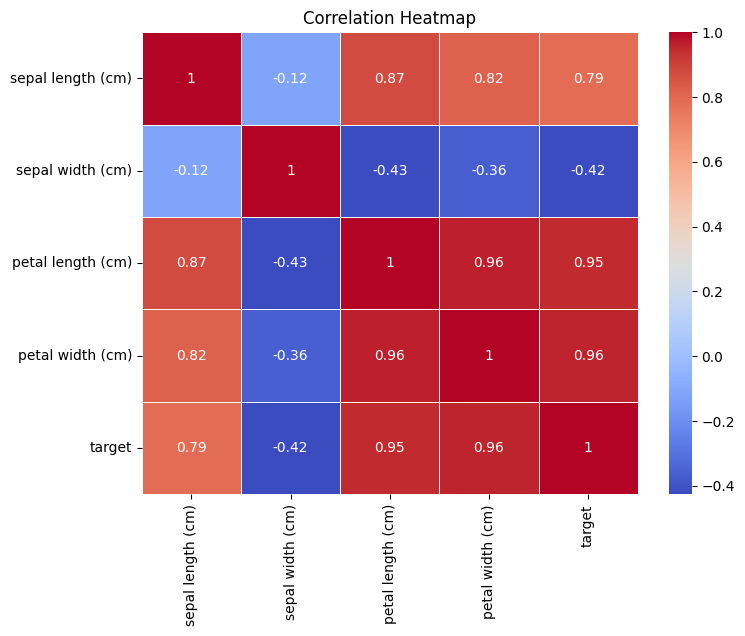

In [20]:

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

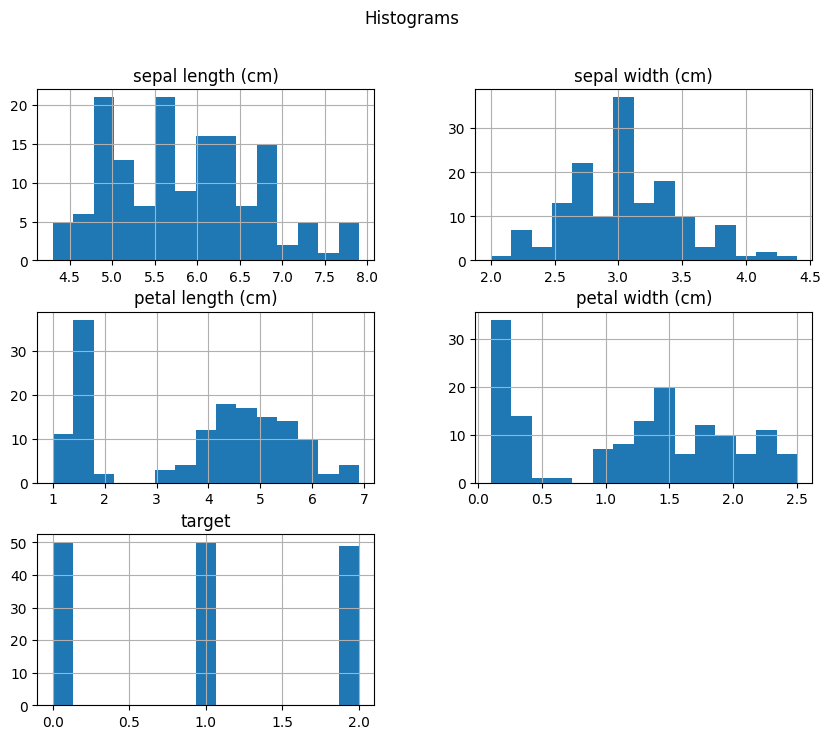

In [21]:

df.hist(figsize=(10, 8), bins=15)
plt.suptitle("Histograms")
plt.show()

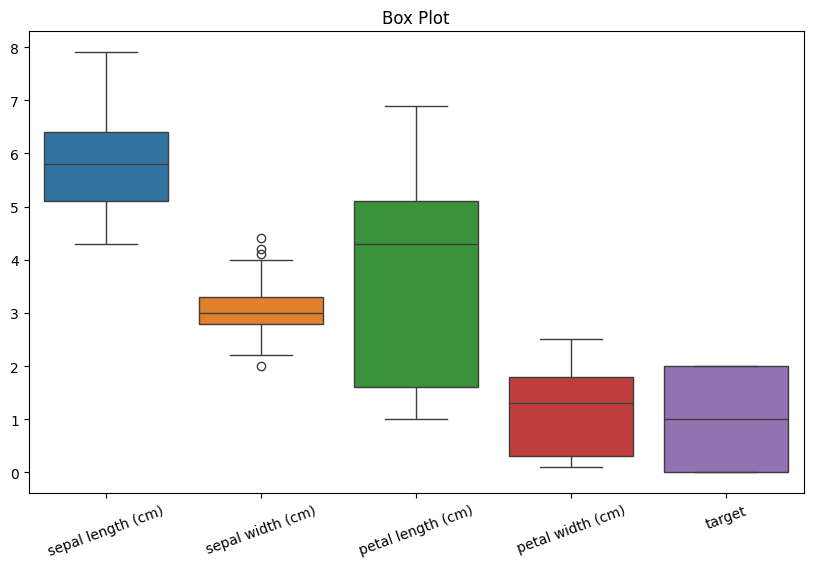

In [22]:

plt.figure(figsize=(10, 6))
sns.boxplot(data=numeric_df)
plt.title("Box Plot")
plt.xticks(rotation=20)
plt.show()

In [23]:

for column in numeric_df.columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]
    print(column, len(outliers))

sepal length (cm) 0
sepal width (cm) 4
petal length (cm) 0
petal width (cm) 0
target 0
